# Lab 2: From Raw Data to ML-Ready Data
## Data Cleaning & Exploratory Data Analysis — Telco Customer Churn

**Name:** _Sania_

**GitHub Repository:** _(link, added before submission)_

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, NumPy, Pandas, and Matplotlib from previous labs. Each section below states the objective and the questions you must answer — **you decide** which functions/plots are appropriate. Do not just run code without interpreting it: every visualization needs a written observation, and every cleaning decision needs a written justification.
>
> Fill in the empty code cells and the *Answer:* / *Observation:* placeholders directly in this notebook. Do not delete the Markdown headings — they are used for grading.

---

## Setup

Import the libraries you'll need and load the dataset. Use the Telco Customer Churn CSV provided for this lab.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")   # update path/filename if different


## Part 1 — The Business Problem

A telecommunications company is losing customers to competitors — this is called **customer churn**. The company wants to understand which customers are likely to leave, so it can intervene early. Before any model can be built, the raw data must be understood, audited for quality issues, and explored.

**Tasks**
1. In 2–3 sentences, state the business problem in your own words, and propose what the target variable likely is.
2. List 5 columns you expect to be useful predictors of churn, and 2 columns you expect to be useless as predictors — justify each choice in one line.
3. Write down 2 questions you personally want this data to answer about customers who churn.

**Answer 1:**
_Company wants to identify if  a customer is leaving or not to figure out a way to retain them. And the target variable is **Churn**._

**Answer 2:**
Tenure — Newer customers may be more likely to leave.
MonthlyCharges — Higher costs can increase churn.
Contract — Month-to-month customers may leave more easily.
InternetService — Service type or quality may affect satisfaction.
Phone service- people maybe leaving it due to poor services, rude customer support.
Gender and Customer are useless feature for the prediction. 
The gender doesnot have noticeable relationship with churn rate.
CustomerID — A unique identifier with no meaningful relationship to churn.

**Answer 3:**
Which type of customers are most likely to churn? For example, based on contract type, tenure, or monthly charges.
What common characteristics do churned customers share? Such as payment method, internet service, or additional services.

---

---

## Part 2 — Exploring the Dataset Structure

Before cleaning or analyzing anything, get an accurate picture of the dataset's shape and contents. Running a command is not the same as understanding its output — you must interpret what you see.

*Concepts/functions you may find useful:* `df.shape`, `df.columns`, `df.dtypes`, `df.info()`, `df.head()`, `df.sample(n)`, `df[col].unique()`, `df[col].nunique()`, `df.describe(include='all')`

**Tasks**

4. How many customers and how many features are in this dataset? List the numerical features and the categorical features separately.
5. Identify any column(s) that are simply identifiers rather than predictive features, and any column(s) whose data type looks wrong for what it represents.
6. Pick 3 categorical columns and report their unique values — do any contain unexpected or inconsistent categories?

In [8]:
print(df.shape)
print(df.dtypes)

(7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


**Answer 4:**
Number of Customers: There are 7043 customers in this dataset.
Number of Features: There are 21 columns total.

Numerical Features:
tenure
MonthlyCharges
SeniorCitizen 
**Categorical Features:**
gender
SeniorCitizen 
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
Churn (Target Variable)


In [13]:
df[df["TotalCharges"].isna() | (df["TotalCharges"] == "")]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


# Task 5 — identify identifier columns / wrong data types
Answer 5:

CustomerID is a unique string assigned to each customer. It has no predictive value for churn because it is essentially a random label.
Total Charges has wrong datatype. Instead it should be float. And it contains blank spaces for customers with a tenure of 0.
SeniorCitizen also has wrong datatype. This is stored as an integer (0 or 1), but it is functionally a categorical binary flag.

# Task 6 — unique values in 3 categorical columns
Gender, SeniorCitizen, and Dependency are categorical columns.
Customers with tenure 0 have blank space. This is an inconsistency in data entry where a 0 or null should likely have been used.

**Observations (Part 2):**
_(summarize what you found — numerical features, categorical features, suspicious columns, etc.)_



Tenure and MontlyCharges are the numerical features and remaining ones are categorical except for CustomerID. The most suspicious column is TotalCharges because it contains hidden blank spaces that cause numerical data to be incorrectly stored as a string type.





---

## Part 3 — Investigating Data Quality

A dataset can look clean at a glance and still hide serious problems. You must actively search for missing values, duplicates, and suspicious values rather than assume there are none.

*Concepts/functions you may find useful:* `df.isnull().sum()`, `df.isnull().mean()*100`, `df.duplicated().sum()`, `df['id_col'].duplicated().sum()`, `df[col].value_counts()`

**Tasks**

7. Report missing values as both a count and a percentage per column. Which missing-value problems do you think require action, and which don't? Justify your reasoning.
8. Check for duplicate rows and duplicate customer IDs separately — are they the same issue or different issues?
9. Find at least one column with a suspicious, invalid, or inconsistently formatted value, and describe how you found it.

In [31]:
# Task 7 — missing values: count and percentage per column
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

print(missing_report)

                  Missing Count  Missing Percentage
customerID                    0                 0.0
gender                        0                 0.0
SeniorCitizen                 0                 0.0
Partner                       0                 0.0
Dependents                    0                 0.0
tenure                        0                 0.0
PhoneService                  0                 0.0
MultipleLines                 0                 0.0
InternetService               0                 0.0
OnlineSecurity                0                 0.0
OnlineBackup                  0                 0.0
DeviceProtection              0                 0.0
TechSupport                   0                 0.0
StreamingTV                   0                 0.0
StreamingMovies               0                 0.0
Contract                      0                 0.0
PaperlessBilling              0                 0.0
PaymentMethod                 0                 0.0
MonthlyCharg

In [35]:
# Task 8 — duplicate rows vs duplicate IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 0
They are different issues. Duplicate rows mean the entire record is repeated, while duplicate customer IDs mean the same customer appears multiple times, potentially with different information.


In [5]:
# Task 9 — investigate a suspicious / invalid value
print(df[df["TotalCharges"].astype(str).str.strip() == ""])

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
488   4472-LVYGI  Female              0     Yes        Yes       0   
753   3115-CZMZD    Male              0      No        Yes       0   
936   5709-LVOEQ  Female              0     Yes        Yes       0   
1082  4367-NUYAO    Male              0     Yes        Yes       0   
1340  1371-DWPAZ  Female              0     Yes        Yes       0   
3331  7644-OMVMY    Male              0     Yes        Yes       0   
3826  3213-VVOLG    Male              0     Yes        Yes       0   
4380  2520-SGTTA  Female              0     Yes        Yes       0   
5218  2923-ARZLG    Male              0     Yes        Yes       0   
6670  4075-WKNIU  Female              0     Yes        Yes       0   
6754  2775-SEFEE    Male              0      No        Yes       0   

     PhoneService     MultipleLines InternetService       OnlineSecurity  ...  \
488            No  No phone service             DSL                  Yes  ... 

**Answer 7 (which missing-value problems need action, and why):**

_Missing TotalCharges values require attention because they occur for new customers and can affect numerical analysis. Other columns with no missing values require no action._

**Answer 8 (duplicate rows vs duplicate IDs — same issue or different?):**

_They are different issues. Duplicate rows mean the entire record is repeated, while duplicate customer IDs mean the same customer appears multiple times, potentially with different information._

**Answer 9 (suspicious value found and how):**

_TotalCharges is a good example. I found values containing blank spaces (" ") even though the column is supposed to contain numerical charges.This indicates an inconsistent data format._

---

## Part 4 — Data Cleaning Decisions

Cleaning is a series of justified decisions, not a fixed recipe. For every issue you fix, you must be able to explain why you chose that method over an alternative.

*Concepts/functions you may find useful:* `pd.to_numeric(s, errors='coerce')`, `df.fillna(value)`, `df.dropna()`, `df.drop_duplicates()`, `df[col].str.strip()`, `df.astype(dtype)`

**Tasks**
10. For every data-quality issue you found in Part 3, record: Problem → Decision → Method Used → Reason.
11. Apply your cleaning decisions to produce an intermediate cleaned dataframe, and confirm (with code output) that each issue is actually resolved.

**Task 10 — Cleaning Decision Log**

| Problem | Decision | Method Used | Reason |
|---|---|---|---|
| _e.g. TotalCharges stored as text_ | _Convert it to numeric_ | _pd.to_numeric(s, errors="coerce")_ | _Charges represent numerical values and should be stored as a numeric datatype_ |
| _Missing TotalCharges for new customers (tenure = 0)_ | _Replace with 0_ | _.fillna(0)_ | _New customers have not accumulated any charges yet_ |
| _Duplicate rows_ | _Remove exact duplicates_ | _.drop_duplicates()_ | _Exact repeated records add no new information_ |

In [15]:
# Task 11 — apply your cleaning decisions here
df_clean = df.copy()
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].str.strip(),
    errors="coerce"
)
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)
df_clean = df_clean.drop_duplicates()

In [44]:
# Task 11 (continued) — confirm each issue is resolved (e.g. re-check isnull().sum(), duplicated().sum(), dtypes)
print("Missing values:")
print(df_clean.isnull().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print(pd.api.types.is_numeric_dtype(df_clean["TotalCharges"]))

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
True


---

## Part 5 — Univariate EDA

Look at individual variables in isolation before looking at relationships. Every chart must be followed by a written interpretation — a graph with no explanation earns no credit.

*Concepts/functions you may find useful:* `df[col].plot(kind='hist')` / `plt.hist()`, `df.boxplot(column=col)`, `df[col].value_counts().plot(kind='bar')`

**Tasks**
12. Visualize the distribution of at least 2 numerical features and 2 categorical features. For each chart, write 1–2 sentences on what you learned.
13. Do any numerical features show outliers or a skewed distribution? What might explain this?

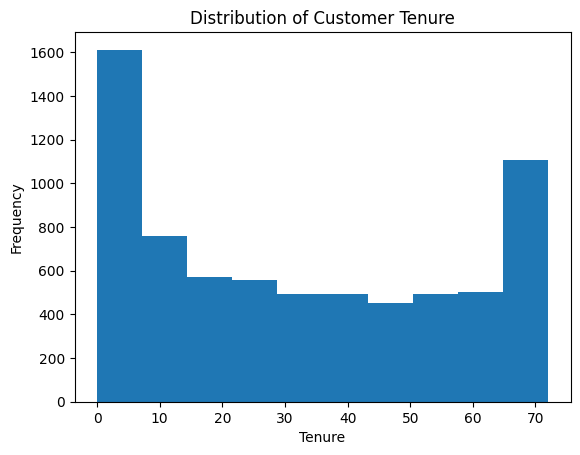

In [49]:
# Task 12 — numerical feature 1: distribution plot
plt.hist(df_clean["tenure"])
plt.xlabel("Tenure")
plt.ylabel("Frequency")
plt.title("Distribution of Customer Tenure")
plt.show()

**Observation:** _(what did you learn from this chart?)_

Tenure is fairly spread across the range, with the highest peaks at the start (new customers) and the end (long-term loyalists).

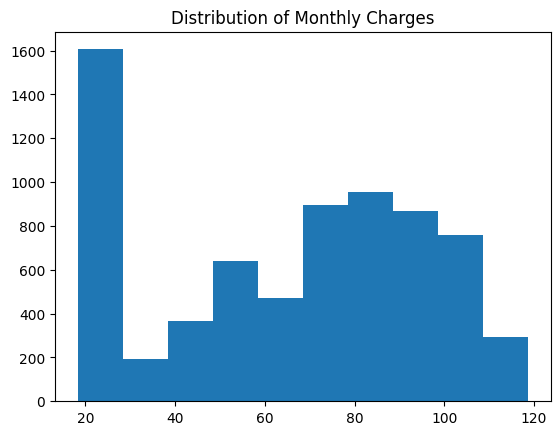

In [50]:
# Task 12 — numerical feature 2: distribution plot
plt.hist(df_clean["MonthlyCharges"])
plt.title("Distribution of Monthly Charges")
plt.show()

**Observation:** _(what did you learn from this chart?)_

The chart shows two distinct peaks, revealing that most customers are either on basic low-cost plans or high-priced tiers.

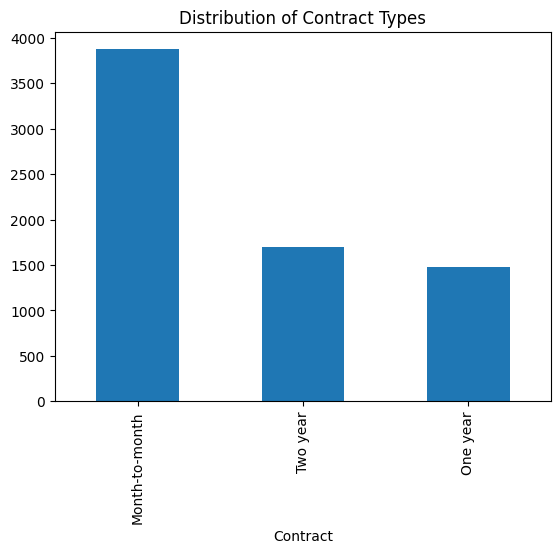

In [57]:
# Task 12 — categorical feature 1: distribution plot
df_clean["Contract"].value_counts().plot(kind="bar")
plt.title("Distribution of Contract Types")
plt.show()

**Observation:** _(what did you learn from this chart?)_

Month-to-month contracts are the most common, while longer-term contracts are less frequent.

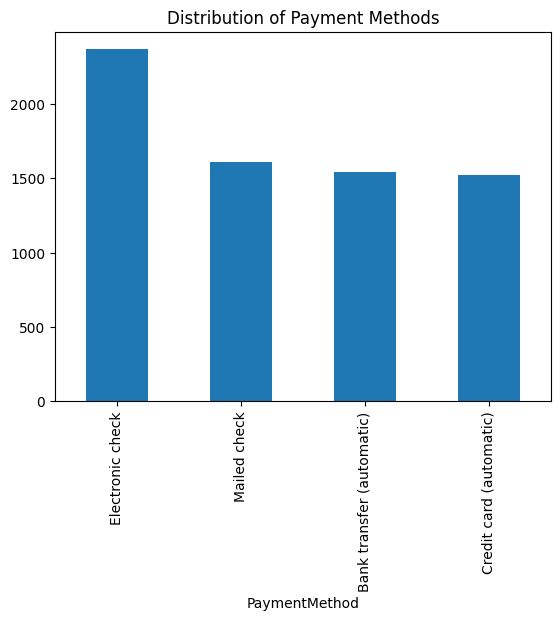

In [58]:
# Task 12 — categorical feature 2: distribution plot
df_clean["PaymentMethod"].value_counts().plot(kind="bar")
plt.title("Distribution of Payment Methods")
plt.show()

**Observation:** _(what did you learn from this chart?)_

Electronic check is the most common payment method.

**Answer 13 (outliers / skew and possible explanation):**

_MonthlyCharges shows some variation and may contain a few unusually high values. TotalCharges is also likely to be right-skewed, because many customers have very short tenures, a large majority have low total payments._

---

## Part 6 — Target Variable Analysis

The `Churn` column is what you will eventually predict. Before Lab 3, you need to understand its distribution — this has direct consequences for how a model should later be trained and evaluated.

*Concepts/functions you may find useful:* `df['Churn'].value_counts()`, `df['Churn'].value_counts(normalize=True)`

**Tasks**

14. Report the number and percentage of churned vs. non-churned customers. Is the target balanced or imbalanced?
15. In 2–3 sentences, explain why class imbalance might matter when a classification model is trained later — do not describe how to fix it, just why it matters.

In [64]:
# Task 14 — churn counts and percentages
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True)*100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Answer 14 (balanced or imbalanced?):**

_The target is imbalanced, since non-churned customers significantly outnumber churned customers._

**Answer 15 (why imbalance might matter later):**

_A model may become biased toward predicting the majority class (No). This can produce high accuracy while still failing to correctly identify many customers who actually churn._

---

## Part 7 — Bivariate Analysis: Features vs. Churn

Now connect individual features to the target. You choose the appropriate visualization or summary for each feature type — a categorical feature is not explored the same way as a numerical one.

*Concepts/functions you may find useful:* `pd.crosstab(df[col], df['Churn'], normalize='index')`, `df.groupby(col)['Churn']...`, `sns.boxplot(x='Churn', y=col, data=df)`

**Tasks**

16. Investigate at least 2 categorical features (e.g. Contract, InternetService, PaymentMethod) against Churn. For each, record: Observation / Evidence / Possible Explanation.
17. Investigate at least 2 numerical features (e.g. tenure, MonthlyCharges) against Churn using the same Observation / Evidence / Possible Explanation format.

In [7]:
# Task 16 — categorical feature 1 vs Churn
pd.crosstab(df["Contract"], df['Churn'],normalize='index')

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


**Observation:** _Month-to-month customers have the highest churn._

_One-year contract customers have lower churn._

_Two-year contract customers have the lowest churn._

**Evidence:** _42.71% of month-to-month customers churned._

_Only 11.27% churned._

_Only 2.83% churned._

**Possible Explanation:** 

_Short-term contracts provide less commitment, making it easier for customers to leave._

_Longer contracts may increase customer commitment and retention._

_Long-term commitment likely reduces the likelihood of switching providers._


In [9]:
# Task 16 — categorical feature 2 vs Churn
pd.crosstab(df["InternetService"], df['Churn'], normalize='index')

Churn,No,Yes
InternetService,,
DSL,0.810409,0.189591
Fiber optic,0.581072,0.418928
No,0.925950,0.074050


**Observation:** 

_Fiber optic customers have the highest churn._

_DSL customers have moderate churn._

_Customers without internet service have the lowest churn._

**Evidence:**

_41.89% of fiber optic customers churned._

_18.96% churned._

_Only 7.41% churned._

**Possible Explanation:** 

_Fiber optic customers may face higher costs or service-related dissatisfaction._

_DSL customers appear more likely to stay than fiber optic customers._

_These customers may have fewer service-related issues or lower monthly costs._

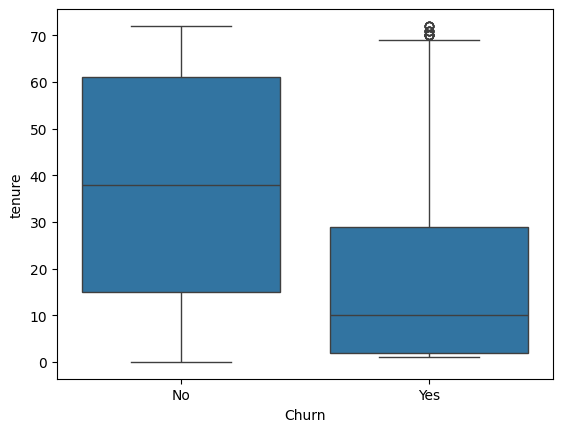

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [10]:
# Task 17 — numerical feature 1 vs Churn
# Tenure vs Churn
sns.boxplot(x='Churn', y='tenure', data=df)
plt.show()

df.groupby('Churn')['tenure'].describe()

**Observation:**

_Customers who churned generally have shorter tenure._

_Non-churned customers have a wider distribution toward higher tenure._

**Evidence:**

_Median tenure is 10 months for churned customers vs. 38 months for non-churned customers._

_75% of non-churned customers have tenure ≤ 61 months, compared with ≤ 29 months for churned customers._

**Possible Explanation:** 

_Newer customers may be less loyal or may leave before developing a long-term relationship with the company._

_Customers who stay longer appear more likely to remain with the company._

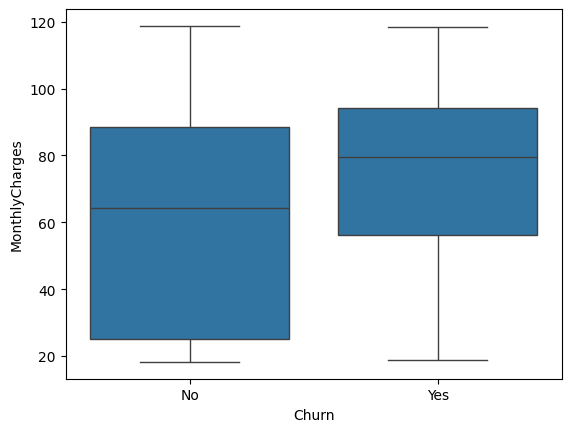

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [13]:
# Task 17 — numerical feature 2 vs Churn
# MonthlyCharges vs Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()

df.groupby('Churn')['MonthlyCharges'].describe()

**Observation:**

_Customers who churned generally have higher monthly charges._

_Churned customers are concentrated at higher monthly charges._

**Evidence:** 

_Median charge is **\$79.65** for churned customers vs. $64.43 for non-churned customers._

_25% of churned customers pay **\$56.15** or less, while 75% pay $94.20 or less._

**Possible Explanation:**

_Higher monthly costs may make customers more likely to leave._

_Customers paying more may perceive the service as less cost-effective._

---

## Part 8 — Correlation & Feature Relationships

Numerical features can be related to each other, not just to the target. Strongly correlated features can cause redundancy problems later, so it's worth knowing about them now.

*Concepts/functions you may find useful:* `df.corr(numeric_only=True)`, `sns.heatmap(corr_matrix, annot=True)`

**Tasks**
18. Compute and visualize the correlation matrix of the numerical features. Which pairs appear most correlated?
19. Does correlation imply causation here? Could any highly correlated features cause problems for a future model? Answer in 2–3 sentences.

In [2]:
# Task 18 — correlation matrix and heatmap
df.corr(numeric_only=True)

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.016567,0.220173
tenure,0.016567,1.000000,0.247900
MonthlyCharges,0.220173,0.247900,1.000000


**Answer 18 (most correlated pairs):**

_The most correlated pair of numerical features is tenure and MonthlyCharges with a correlation coefficient of approximately 0.2479. The next most correlated pair is SeniorCitizen and MonthlyCharges at approximately 0.2202._

**Answer 19 (correlation vs. causation; potential problems):**

_No, correlation does not imply causation; for example, a longer tenure doesn't necessarily cause higher monthly charges, it simply shows they tend to increase together. While very high correlations (multicollinearity) can sometimes make model coefficients unstable and difficult to interpret, the correlations in this dataset are quite low (all below 0.3) and are unlikely to cause any significant issues for a future model._

---

## Part 9 — Data Leakage Awareness

In Lab 3 you will train a classifier. Before that, you must check whether any column contains information that would not realistically be available at the moment of prediction — using such a column would make a model look artificially accurate.

**Tasks**

20. Inspect the columns for anything that looks like it could only be known after a customer has already churned, or that is purely an identifier. List any suspects and explain your reasoning.
21. In 2–3 sentences, explain what would go wrong if such a column were left in the model's input features.

**Answer 20 (suspect columns and reasoning):**

_customerID: This is a pure identifier. It contains no behavioral information that could generalize to other customers. It simply labels a specific row.
TotalCharges: This is the total amount of money a customer has paid over time. If a customer cancels their service, this number stops growing. This can "leak" the answer to the model because a finished total often belongs to someone who has already left._

**Answer 21 (what would go wrong):**

_If you include these columns, the model will essentially "cheat" by looking at information that is only available after a customer has already churned. This creates a model that looks perfect on paper but fails in the real world because it can't predict which current customers are about to leave._

---

## Part 10 — ML-Readiness Checklist

Summarize every column's fate in a single table. This is the bridge between EDA and modeling — Lab 3 will use this table directly.

**Task**
22. Complete the ML-readiness table for **every** column in the dataset.

| Column | Type | Role | Action | Reason |
|---|---|---|---|---|
| Churn | Categorical | Target | Keep | The variable we are trying to predict. |
| customerID | Identifier | — | Remove | Unique ID with no predictive value; causes overfitting. |
| tenure | Numerical | Feature | Keep | Strong indicator of loyalty. |
| Contract | Categorical | Feature | Keep | Determines customer commitment level |
| gender | Categorical | Feature | Keep | Demographic info; needs encoding. |
| SeniorCitizen | Categorical | Feature | Keep | Binary indicator (0 or 1); already in numerical format. |
| Partner | Categorical | Feature | Keep | Personal status; needs encoding. |
| Dependents | Categorical | Feature | Keep | Personal status; needs encoding. |
| PhoneService | Categorical | Feature | Keep | Service usage |
| MultipleLines | Categorical | Feature | Keep | Service usage details |
| InternetService	 | Categorical | Feature | Keep | Service type; important for churn analysis. |
| OnlineSecurity | Categorical | Feature | Keep | Add-on service; helps identify "sticky" customers. |
| OnlineBackup | Categorical | Feature | Keep | Add-on service |
| DeviceProtection | Categorical | Feature | Keep | Add-on service |
| TechSupport | Categorical | Feature | Keep | Add-on service |
| StreamingTV	 | Categorical | Feature | Keep | Service usage details |
| StreamingMovies | Categorical | Feature | Keep | Service usage details |
| PaperlessBilling	 | Categorical | Feature | Keep | Billing preference |
| PaymentMethod | Categorical | Feature | Keep | Billing preference |
| MonthlyCharges | Categorical | Feature | Keep | Cost factor |
| TotalCharges | Categorical | - | Remove | Potential data leakage; reveals if a lifecycle has ended. |



---

## Part 11 — Building the Clean Dataset

Bring together every cleaning decision into one final dataframe, `clean_df`, that Lab 3 can load directly.

> Do **not** split into train/test, encode categorical variables, or train any model — that happens in Lab 3.

**Tasks**

23. Produce `clean_df` with correct data types, missing values handled, duplicates handled, and irrelevant identifier columns removed where justified. Save it (e.g. `clean_churn.csv`) alongside your notebook.
24. Print `df.info()` (or equivalent) for `clean_df` as final proof that every issue identified earlier has been resolved.

In [9]:
# Task 23 — assemble clean_df from your cleaning decisions
df_clean = df_clean.drop(columns=['customerID'])
print(df_clean)

# ... apply your cleaning steps here ...

# Save the cleaned dataset
df_clean.to_csv("clean_churn.csv", index=False)


      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No          Yes   
1      

In [16]:
# Task 24 — final proof: info() / isnull().sum() / duplicated().sum() on clean_df
df_clean.info()
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

---

## Part 12 — Key Findings & Final Reflection

Step back from the code and summarize what you actually learned about this dataset and this problem.

**Task 25 — Five Important Findings**

Repeat this block for each of your five findings.

**Finding 1**
- Observation: _Customers on month-to-month contracts are significantly more likely to leave._
- Evidence: _In the Contract column, the churn rate for monthly plans is much higher than for one-year or two-year contracts._
- Interpretation: _Short-term flexibility makes it very easy for customers to switch to competitors; the business should offer discounts to move these customers into long-term contracts._

**Finding 2**
- Observation: _Churn is highest during the first few months of service._
- Evidence: _A distribution of the tenure column shows a large spike in churn for customers with 0–6 months of service._
- Interpretation: _The "onboarding" phase is critical. Better customer support or "new member" rewards during the first six months could prevent these early departures._

**Finding 3**
- Observation: _Customers with higher monthly bills tend to churn more often._
- Evidence: _The average for MonthlyCharges is noticeably higher for customers who churned compared to those who stayed._
- Interpretation: _Price sensitivity is a major factor. Customers paying for premium plans may feel they aren't getting enough value and might be looking for cheaper alternatives._

**Finding 4**
- Observation: _Customers who use "sticky" services like Tech Support or Online Security are much more loyal._
- Evidence: _Churn rates are significantly lower for customers who have "Yes" in the TechSupport or OnlineSecurity columns._
- Interpretation: _These add-on services increase the customer's "switching cost" (it’s harder to leave when you rely on their security/support). Bundling these for free could be a great retention tool._

**Finding 5**
- Observation: _Fiber optic internet users leave at a higher rate than DSL users._
- Evidence: _When looking at InternetService, Fiber optic customers have a disproportionately high churn rate despite having faster speeds._
- Interpretation: _This suggests there may be technical issues or service quality frustrations specifically with the Fiber network, or that the Fiber price point is too high compared to the competition._

---

**Task 26 — Final Reflection Questions**

1. What was the most important data-quality issue you found?

   _The most important issue was that the TotalCharges column was often stored as a "string" (text) rather than a number, because it contained empty spaces for customers with zero tenure. This would cause errors in mathematical calculations unless those blanks are handled and the column is converted to a numeric format._
3. What was the most interesting pattern you discovered?

   _The "Fiber Optic Paradox" was very interesting: customers with Fiber Optic internet (which is faster) churned at a much higher rate than those with slower DSL service. This suggests that speed isn't everything and that these customers might be frustrated by high prices or unreliable service._
5. Which feature seems most useful for predicting churn?

   _Contract appears to be the most useful feature. There is a massive difference in churn rates between "Month-to-month" customers and those on "One-year" or "Two-year" plans, making it a very strong signal for a machine learning model._
7. Which feature should probably not be used, and why?

   _customerID should not be used. It is a unique identifier for each person and contains no actual behavioral patterns; including it would lead to "overfitting," where the model simply memorizes names/IDs instead of learning why customers actually leave._
9. What preprocessing will be required before ML modeling (conceptually — do not implement it)?

   _Two main steps are needed: Categorical Encoding to convert text-based columns (like "Yes/No" or "Contract" types) into numbers the computer can understand, and Feature Scaling to ensure that columns with large numbers (like MonthlyCharges) don't unfairly outweigh columns with small numbers (like tenure)._
11. What would you do next if you had another 3 hours?

    _I would perform Feature Engineering to create new indicators, such as the ratio of MonthlyCharges to total household income (if available) or identifying "at-risk" combinations (e.g., Fiber Optic users on Month-to-Month plans). I would also investigate why Fiber Optic users are leaving by looking at their TechSupport usage._

---

## Bonus Tasks (Optional)

- Create one additional meaningful visualization not required above.
- Investigate a surprising customer subgroup you didn't expect to find.
- Calculate churn rate across a combination of 2+ customer segments at once.
- Identify one possible feature-engineering opportunity for Lab 3.
- Identify one possible source of bias in this dataset.

In [ ]:
# Bonus — optional exploration


---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Completed all 26 tasks above, with written interpretation for every chart and decision
- [ ] A working `clean_df`, saved as `clean_churn.csv`
- [ ] A completed ML-readiness table (Part 10) covering every column
- [ ] Five Key Findings written (Part 12)
- [ ] Answered all six Final Reflection questions
- [ ] Committed and pushed this notebook + `clean_churn.csv` to your GitHub repository
- [ ] Added your GitHub repository link at the top of this notebook